<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Haybarn](https://query.farm/products/haybarn/) · [Setup guide](README.md)

# 01 · Compare exchange-rate changes without mixing units

A yen quote is numerically much larger than a dollar quote. That alone says nothing
about how either currency changed against the euro. Can we compare their paths
while keeping the original quotation, dates and missing observations honest?

We will discover the ECB exchange-rate key, check the returned series metadata,
inspect daily coverage, then put each series on a shared starting value of 100.
The final experiment asks how much the measured change depends on the start date.
These are descriptive historical comparisons of ECB reference rates.

The ECB quotes currencies against the euro and publishes reference rates for
information purposes, generally on working days. They are not executable market
prices. See the [ECB reference-rate explanation](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/index.en.html).

## Choose the comparison

The default requests **USD, GBP and JPY per EUR** over **90 calendar days** ending
yesterday in UTC. `END_DATE = None` resolves once at run start; a date override must
use `YYYY-MM-DD` and precede today. Both source endpoints are **inclusive**. These are
source observation dates, not timestamps of publication or retrieval.

Choose 2–5 distinct uppercase non-EUR currency codes and 14–366 calendar days.
Availability depends on the ECB. Edit this cell, then **Restart Kernel → Run All**.
Saved outputs are a successful **live public ECB** run. No API key, synthetic data,
recorded-response mode or automatic fallback is used.

In [1]:
CURRENCIES = ["USD", "GBP", "JPY"]
LOOKBACK_DAYS = 90  # Inclusive calendar-day request span, 14-366
END_DATE = None  # Inclusive ISO date; None selects yesterday in UTC

In [2]:
import json
import os
import sys
from datetime import UTC, datetime
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))
import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display

from notebook_support import API_URL, COLORS, chart, configure, prose, set_theme, sql_text

started = datetime.now(UTC)
start_date, end_date = configure(CURRENCIES, LOOKBACK_DAYS, END_DATE, started.date())
artifact_dir = Path(os.environ.get("ECB_NOTEBOOK_ARTIFACT_DIR", NOTEBOOK_DIR / "build/default/artifacts"))
source = f"Source: ECB public SDMX API via VGI · run started {started:%Y-%m-%d %H:%M:%S} UTC"
palette = dict(zip(CURRENCIES, sns.color_palette("colorblind", len(CURRENCIES)), strict=True))
palette.update({c: COLORS[c] for c in CURRENCIES if c in COLORS})
requested_sql = ", ".join(f"({sql_text(c)})" for c in CURRENCIES)
set_theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-ecb-portable-bc9firpv/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-ecb-portable-bc9firpv/notebooks/pyproject.toml.

In [3]:
prose(
    f"**LIVE · official public ECB API** · run started **{started:%Y-%m-%d %H:%M:%S} UTC**.  \n"
    f"Request: **{start_date} through {end_date}, inclusive** ({LOOKBACK_DAYS} calendar days).  \n"
    "The worker is launched from pinned GitHub release v0.1.0 through uvx. "
    "Setup pins the official upstream endpoint and disables an inherited loopback test setting. "
    "Independent metadata and observation responses are not an atomic snapshot. "
    "The run clock is retrieval context, not a source release timestamp."
)

**LIVE · official public ECB API** · run started **2026-11-14 04:10:44 UTC**.  
Request: **2026-08-16 through 2026-11-13, inclusive** (90 calendar days).  
The worker is launched from pinned GitHub release v0.1.0 through uvx. Setup pins the official upstream endpoint and disables an inherited loopback test setting. Independent metadata and observation responses are not an atomic snapshot. The run clock is retrieval context, not a source release timestamp.

## Connect to the real worker

The literal launch below installs the **v0.1.0** GitHub release through `uvx`, pins
**vgi-python 0.51.1**, and runs its entry point over stdio. It selects the official
ECB endpoint and disables inherited loopback fixture access. Python configures only
the TLS trust bundle and request parameters. You need `uv`, Git and POSIX `env` on
PATH; no local worker checkout is required. The notebook environment independently
pins published Haybarn **2.0.0rc11**.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ecb' (TYPE vgi, LOCATION 'env -u ECB_ALLOW_INSECURE_HTTP ECB_API_BASE_URL=https://data-api.ecb.europa.eu/service uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-ecb@v0.1.0 vgi-ecb-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


## Discover what each key position means

Start with only the `EXR` dataflow, then ask for its ordered dimensions.
`TIME_PERIOD` identifies observations; it does **not** belong in the dotted series key,
even when the source assigns it a numeric position. We filter by `is_time`, not by
whether `position` is NULL. The `+` syntax requests multiple currency values within
one dimension.

In [5]:
%%sql
CREATE OR REPLACE TABLE flow_info AS
SELECT * FROM ecb.main.datasets(flow := 'EXR', max_rows := 10);
CREATE OR REPLACE TABLE dimension_info AS
SELECT * FROM ecb.main.dimensions('EXR', max_rows := 20);
SELECT flow, name, structure_id, structure_version FROM flow_info;
SELECT dimension, position, is_time, codelist, codelist_agency, codelist_version
FROM dimension_info ORDER BY position NULLS LAST, dimension;

,dimension,position,is_time,codelist,codelist_agency,codelist_version
0,FREQ,1,False,CL_FREQ,ECB,1.0
1,CURRENCY,2,False,CL_CURRENCY,ECB,1.0
2,CURRENCY_DENOM,3,False,CL_CURRENCY,ECB,1.0
3,EXR_TYPE,4,False,CL_EXR_TYPE,ECB,1.0
4,EXR_SUFFIX,5,False,CL_EXR_SUFFIX,ECB,1.0
5,TIME_PERIOD,6,True,None,None,None


In [6]:
%%sql key_parts <<
CREATE OR REPLACE TABLE requested_currencies AS
SELECT currency FROM (VALUES {{ requested_sql }}) AS requested(currency);
CREATE OR REPLACE TABLE key_parts AS
SELECT dimension, position, codelist, codelist_agency, codelist_version,
       CASE dimension
         WHEN 'FREQ' THEN 'D'
         WHEN 'CURRENCY' THEN (SELECT string_agg(currency, '+' ORDER BY currency) FROM requested_currencies)
         WHEN 'CURRENCY_DENOM' THEN 'EUR'
         WHEN 'EXR_TYPE' THEN 'SP00'
         WHEN 'EXR_SUFFIX' THEN 'A'
       END AS selected_code
FROM dimension_info WHERE NOT is_time;
SELECT * FROM key_parts ORDER BY position;

In [7]:
display(key_parts[["position", "dimension", "selected_code", "codelist"]])
expected_dimensions = {"FREQ", "CURRENCY", "CURRENCY_DENOM", "EXR_TYPE", "EXR_SUFFIX"}
assert set(key_parts.dimension) == expected_dimensions, "EXR dimensions changed; inspect the discovered structure."
assert key_parts.selected_code.notna().all() and key_parts.position.is_unique
code_refs = {r.dimension: r for r in key_parts.itertuples()}
prose(
    "The selected components are joined in the source's declared order. "
    "Before requesting observations, we resolve code labels from the returned code-list references. "
    "Each request uses that list's own agency and version."
)

,position,dimension,selected_code,codelist
0,1,FREQ,D,CL_FREQ
1,2,CURRENCY,GBP+JPY+USD,CL_CURRENCY
2,3,CURRENCY_DENOM,EUR,CL_CURRENCY
3,4,EXR_TYPE,SP00,CL_EXR_TYPE
4,5,EXR_SUFFIX,A,CL_EXR_SUFFIX


The selected components are joined in the source's declared order. Before requesting observations, we resolve code labels from the returned code-list references. Each request uses that list's own agency and version.

In [8]:
%%sql
CREATE OR REPLACE TABLE currency_labels AS
SELECT code, name FROM ecb.main.codes(
  {{ sql_text(code_refs['CURRENCY'].codelist) }},
  agency := {{ sql_text(code_refs['CURRENCY'].codelist_agency) }},
  version := {{ sql_text(code_refs['CURRENCY'].codelist_version) }}, max_rows := 1000);
SELECT r.currency, c.name FROM requested_currencies r
LEFT JOIN currency_labels c ON r.currency = c.code ORDER BY r.currency;
SELECT 'EXR_TYPE' AS dimension, code, name FROM ecb.main.codes(
  {{ sql_text(code_refs['EXR_TYPE'].codelist) }},
  agency := {{ sql_text(code_refs['EXR_TYPE'].codelist_agency) }},
  version := {{ sql_text(code_refs['EXR_TYPE'].codelist_version) }}, max_rows := 1000)
WHERE code = 'SP00'
UNION ALL
SELECT 'EXR_SUFFIX', code, name FROM ecb.main.codes(
  {{ sql_text(code_refs['EXR_SUFFIX'].codelist) }},
  agency := {{ sql_text(code_refs['EXR_SUFFIX'].codelist_agency) }},
  version := {{ sql_text(code_refs['EXR_SUFFIX'].codelist_version) }}, max_rows := 1000)
WHERE code = 'A';

,dimension,code,name
0,EXR_TYPE,SP00,Spot
1,EXR_SUFFIX,A,Average


In [9]:
%%sql selection <<
SELECT string_agg(selected_code, '.' ORDER BY position) AS sdmx_key FROM key_parts;

In [10]:
sdmx_key = selection.sdmx_key.iloc[0]
prose(
    f"**Selected key: `{sdmx_key}`.** `D` selects daily observations, with EUR as the denominator. "
    "The rate type and suffix labels above distinguish this selection from other EXR measures. "
    "Next check the actual series titles and units, rather than inferring units from the size of a value."
)

**Selected key: `D.GBP+JPY+USD.EUR.SP00.A`.** `D` selects daily observations, with EUR as the denominator. The rate type and suffix labels above distinguish this selection from other EXR measures. Next check the actual series titles and units, rather than inferring units from the size of a value.

## Confirm the series before comparing them

`series()` requests metadata without observations. The query is bounded by the same
key and dates used below. A missing currency remains visible through the left join.
For each selected daily series we require the currency numerator, EUR denominator,
and expected rate-type dimensions; an unexpected source change stops the analysis.

In [11]:
%%sql metadata <<
CREATE OR REPLACE TABLE series_info AS
SELECT * FROM ecb.main.series('EXR', {{ sql_text(sdmx_key) }},
  start_period := {{ sql_text(start_date) }}, end_period := {{ sql_text(end_date) }}, max_rows := 10);
SELECT r.currency, s.series_key, s.title, s.frequency, s.unit, s.unit_multiplier,
       json_extract_string(s.dimensions_json, '$.CURRENCY_DENOM') AS denominator,
       json_extract_string(s.dimensions_json, '$.EXR_TYPE') AS rate_type,
       json_extract_string(s.dimensions_json, '$.EXR_SUFFIX') AS suffix
FROM requested_currencies r LEFT JOIN series_info s
  ON r.currency = json_extract_string(s.dimensions_json, '$.CURRENCY')
ORDER BY r.currency;

In [12]:
display(metadata[["currency", "series_key", "title", "unit", "unit_multiplier", "denominator"]])
assert len(metadata) == len(CURRENCIES) and metadata.currency.is_unique
assert metadata.series_key.notna().all(), (
    "A requested currency has no matching series; choose another or widen the dates."
)
assert metadata.frequency.eq("D").all() and metadata.denominator.eq("EUR").all()
assert metadata.unit.eq(metadata.currency).all() and metadata.unit_multiplier.notna().all()
assert metadata.rate_type.eq("SP00").all() and metadata.suffix.eq("A").all()
prose(
    "**Quotation: currency units for one euro.** The worker preserves the published `value` "
    "and base-ten `unit_multiplier`; our conversion is `value × 10^unit_multiplier`. "
    "A higher quote means one euro buys more of that currency. It does not mean that currency "
    "strengthened against the euro. Different numerators need separate raw-value axes."
)

,currency,series_key,title,unit,unit_multiplier,denominator
0,GBP,D.GBP.EUR.SP00.A,Pound sterling/Euro ECB reference exchange rate,GBP,0,EUR
1,JPY,D.JPY.EUR.SP00.A,Japanese yen/Euro ECB reference exchange rate,JPY,0,EUR
2,USD,D.USD.EUR.SP00.A,US dollar/Euro ECB reference exchange rate,USD,0,EUR


**Quotation: currency units for one euro.** The worker preserves the published `value` and base-ten `unit_multiplier`; our conversion is `value × 10^unit_multiplier`. A higher quote means one euro buys more of that currency. It does not mean that currency strengthened against the euro. Different numerators need separate raw-value axes.

## Retrieve once, then audit availability

We materialize one bounded observation response. `max_rows = 2000` exceeds the
maximum 5 × 366 daily records permitted by the parameters; it is a protective cap,
not pagination. Source filtering comes from the function arguments. Later SQL
filters do not reduce the API request.

We retain the original value text, observation status and action. The analysis uses
positive, finite, status-`A` observations (the source's normal-value code), and never
turns missing observations into zero. The diagnostics separate absent dates,
returned missing values and values excluded by status. A weekend or closure can
explain an absent date; this notebook does not infer a complete ECB holiday calendar.

In [13]:
%%sql
CREATE OR REPLACE TABLE raw_observations AS
SELECT * FROM ecb.main.observations('EXR', {{ sql_text(sdmx_key) }},
  start_period := {{ sql_text(start_date) }}, end_period := {{ sql_text(end_date) }},
  include_history := false, max_rows := 2000);
CREATE OR REPLACE TABLE observations AS
SELECT *, try_cast(period AS DATE) AS obs_date,
       json_extract_string(dimensions_json, '$.CURRENCY') AS currency,
       json_extract_string(dimensions_json, '$.CURRENCY_DENOM') AS denominator,
       value * power(10.0, unit_multiplier) AS units_per_eur,
       coalesce(dataset_action <> 'Delete' AND observation_status = 'A'
         AND value > 0 AND isfinite(value) AND unit_multiplier IS NOT NULL
         AND try_cast(period AS DATE) IS NOT NULL, false) AS usable
FROM raw_observations;
SELECT currency, coalesce(observation_status, '(missing)') AS observation_status,
       dataset_action, count(*) AS rows, count(value) AS numeric_values
FROM observations GROUP BY ALL ORDER BY currency, observation_status, dataset_action;

,currency,observation_status,dataset_action,rows,numeric_values
0,GBP,A,Replace,65,65
1,JPY,A,Replace,65,65
2,USD,A,Replace,65,65


In [14]:
%%sql coverage <<
SELECT r.currency, count(o.series_key) AS returned_rows,
       count(o.value) AS numeric_values,
       count(*) FILTER (WHERE o.series_key IS NOT NULL AND o.value IS NULL) AS missing_values,
       count(*) FILTER (WHERE o.series_key IS NOT NULL AND NOT o.usable) AS excluded_rows,
       count(*) FILTER (WHERE o.usable) AS usable_rows,
       min(o.obs_date) FILTER (WHERE o.usable) AS first_usable,
       max(o.obs_date) FILTER (WHERE o.usable) AS last_usable,
       {{ LOOKBACK_DAYS }} - count(DISTINCT o.obs_date) AS calendar_dates_without_rows
FROM requested_currencies r LEFT JOIN observations o USING (currency)
GROUP BY r.currency ORDER BY r.currency;

In [15]:
retrieved = datetime.now(UTC)
display(coverage)
assert coverage.usable_rows.ge(2).all(), "Each currency needs at least two usable observations in this window."
prose(
    f"Observations finished loading at **{retrieved:%Y-%m-%d %H:%M:%S} UTC**. "
    f"The response contains **{coverage.returned_rows.sum():,} rows**, including "
    f"**{coverage.missing_values.sum():,} missing numeric values** and "
    f"**{coverage.excluded_rows.sum():,} rows excluded** by the stated policy. "
    "Absent dates are counted separately. We will use the intersection of usable dates "
    "so every indexed comparison starts and ends on the same observations."
)

,currency,returned_rows,numeric_values,missing_values,excluded_rows,usable_rows,first_usable,last_usable,calendar_dates_without_rows
0,GBP,65,65,0,0,65,2026-08-17,2026-11-13,25
1,JPY,65,65,0,0,65,2026-08-17,2026-11-13,25
2,USD,65,65,0,0,65,2026-08-17,2026-11-13,25


Observations finished loading at **2026-11-14 04:10:56 UTC**. The response contains **195 rows**, including **0 missing numeric values** and **0 rows excluded** by the stated policy. Absent dates are counted separately. We will use the intersection of usable dates so every indexed comparison starts and ends on the same observations.

In [16]:
%%sql checks <<
SELECT count(*) AS returned_rows,
       count(DISTINCT (series_key, period)) AS unique_series_periods,
       count(*) FILTER (WHERE obs_date NOT BETWEEN {{ sql_text(start_date) }}::DATE
         AND {{ sql_text(end_date) }}::DATE OR obs_date IS NULL) AS invalid_dates,
       count(*) FILTER (WHERE currency NOT IN (SELECT currency FROM requested_currencies)
         OR currency IS NULL OR unit IS DISTINCT FROM currency
         OR denominator IS DISTINCT FROM 'EUR' OR frequency IS DISTINCT FROM 'D'
         OR unit_multiplier IS NULL) AS invalid_units,
       max(abs(try_cast(value_text AS DOUBLE) - value)) AS maximum_parse_difference
FROM observations;

In [17]:
assert checks.returned_rows.iloc[0] == checks.unique_series_periods.iloc[0], (
    "Duplicate series/date rows require a vintage policy."
)
assert checks.invalid_dates.iloc[0] == 0 and checks.invalid_units.iloc[0] == 0
assert checks.maximum_parse_difference.iloc[0] < 1e-12
assert checks.returned_rows.iloc[0] < 2000, "Output cap reached; narrow the request."
prose(
    "**Data checks passed:** series/date identifiers are unique; dates stay within the inclusive "
    "request; units match the selected numerator and EUR denominator; parsed original values agree "
    "with the worker's doubles. We requested current observations, not an inferred revision history."
)

**Data checks passed:** series/date identifiers are unique; dates stay within the inclusive request; units match the selected numerator and EUR denominator; parsed original values agree with the worker's doubles. We requested current observations, not an inferred revision history.

## First see the original units

Separate panels retain the actual quoted magnitudes. Their **vertical scales are
independent** and may be truncated for readability; compare the labels, not line
height or apparent slope across panels. Blank calendar days stay missing, so the
lines break rather than filling weekends or unavailable values.

In [18]:
%%sql raw_plot <<
WITH calendar AS (
  SELECT generate_series::DATE AS obs_date
  FROM generate_series({{ sql_text(start_date) }}::DATE, {{ sql_text(end_date) }}::DATE, INTERVAL 1 DAY)
)
SELECT c.obs_date, r.currency, CASE WHEN o.usable THEN o.units_per_eur END AS units_per_eur
FROM calendar c CROSS JOIN requested_currencies r
LEFT JOIN observations o ON o.obs_date = c.obs_date AND o.currency = r.currency
ORDER BY r.currency, c.obs_date;

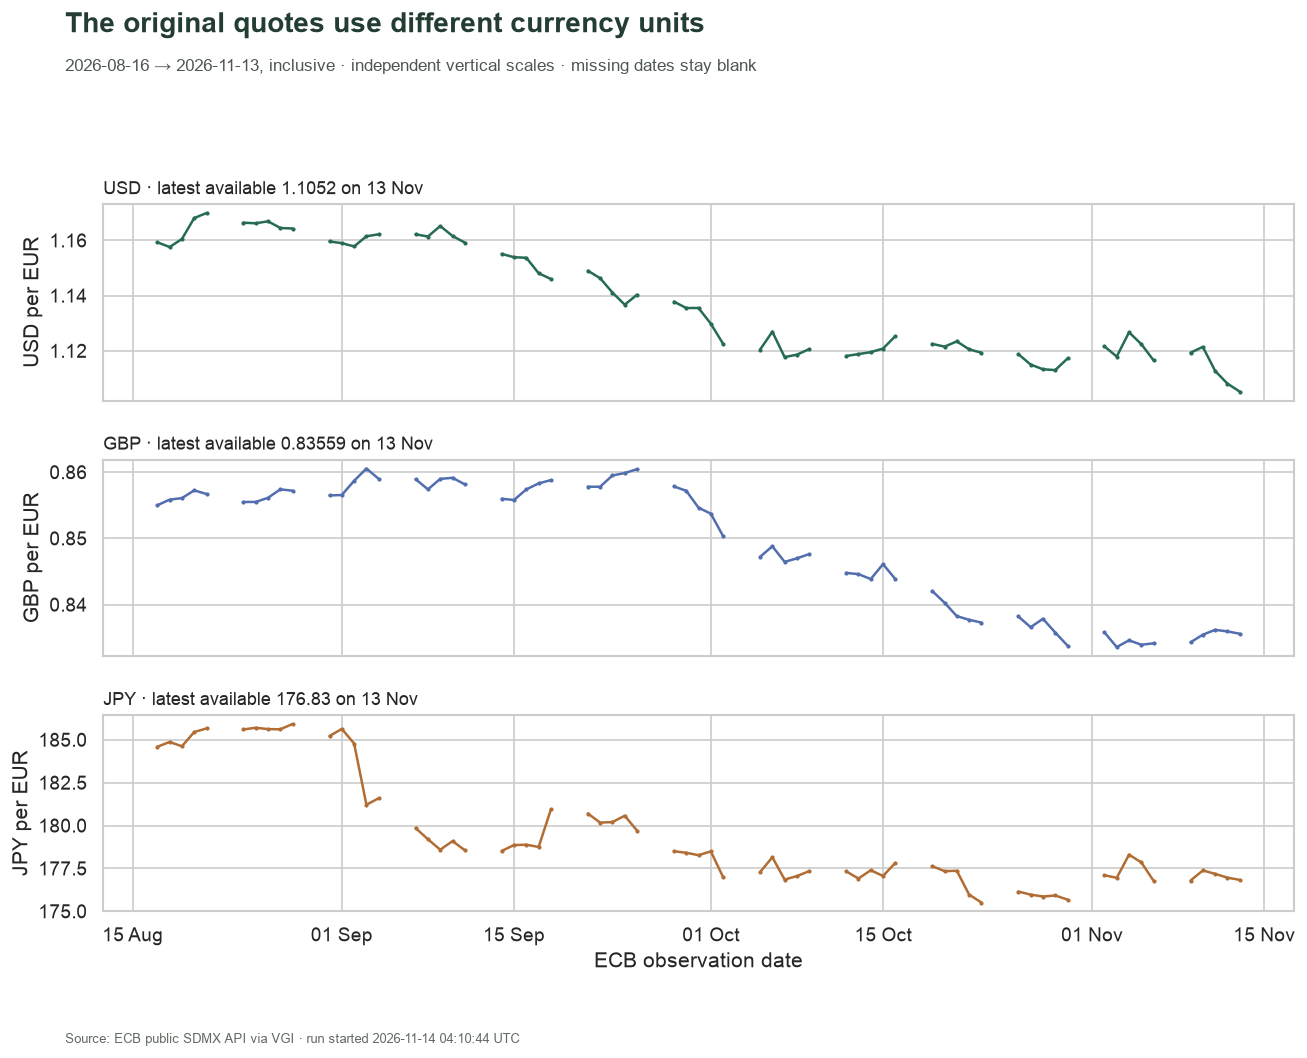

In [19]:
fig, axes = plt.subplots(len(CURRENCIES), 1, figsize=(11.5, 3.0 * len(CURRENCIES)), sharex=True)
for ax, currency in zip(axes, CURRENCIES, strict=True):
    frame = raw_plot[raw_plot.currency == currency]
    ax.plot(frame.obs_date, frame.units_per_eur, color=palette[currency], marker=".", markersize=3, linewidth=1.5)
    last = frame.dropna().iloc[-1]
    ax.set_ylabel(f"{currency} per EUR")
    ax.set_title(
        f"{currency} · latest available {last.units_per_eur:,.5g} on {last.obs_date:%d %b}", loc="left", fontsize=11
    )
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[-1].set_xlabel("ECB observation date")
chart(
    fig,
    "01_original_units",
    "The original quotes use different currency units",
    f"{start_date} → {end_date}, inclusive · independent vertical scales · missing dates stay blank",
    source,
    artifact_dir,
)

## Give every series the same starting point

Restrict to dates where **all selected currencies** have usable values. Index each
quote as `100 × quote / first_common_quote`. This removes the arbitrary unit scale;
it does not change which currency is in the numerator. An index above 100 means
more units of that currency per euro than on the common starting date.

The SQL also calculates the inverse-quote percentage change, in **EUR per currency
unit**. It equals `100 × (first_quote / last_quote − 1)`; percentage changes under
reciprocation are not exactly equal and opposite.

In [20]:
%%sql indexed <<
CREATE OR REPLACE TABLE common_dates AS
SELECT obs_date FROM observations WHERE usable
GROUP BY obs_date HAVING count(DISTINCT currency) = {{ CURRENCIES | length }};
CREATE OR REPLACE TABLE indexed AS
SELECT o.currency, o.obs_date, o.units_per_eur,
       first_value(o.units_per_eur) OVER (PARTITION BY o.currency ORDER BY o.obs_date) AS base_quote,
       100 * o.units_per_eur / first_value(o.units_per_eur)
         OVER (PARTITION BY o.currency ORDER BY o.obs_date) AS quote_index
FROM observations o INNER JOIN common_dates c USING (obs_date)
WHERE o.usable;
SELECT * FROM indexed ORDER BY currency, obs_date;

In [21]:
%%sql summary <<
CREATE OR REPLACE TABLE summary AS
SELECT currency, count(*) AS common_observations, min(obs_date) AS first_date,
       max(obs_date) AS last_date, arg_min(units_per_eur, obs_date) AS first_quote,
       arg_max(units_per_eur, obs_date) AS last_quote,
       100 * (arg_max(units_per_eur, obs_date) / arg_min(units_per_eur, obs_date) - 1) AS quote_change_pct,
       100 * (arg_min(units_per_eur, obs_date) / arg_max(units_per_eur, obs_date) - 1) AS inverse_change_pct
FROM indexed GROUP BY currency;
SELECT * FROM summary ORDER BY currency;

In [22]:
assert not indexed.empty and summary.common_observations.ge(2).all(), (
    "Fewer than two common usable dates; widen the window."
)
assert summary.common_observations.nunique() == summary.first_date.nunique() == summary.last_date.nunique() == 1
assert np.allclose(indexed.groupby("currency").first().quote_index, 100)
assert np.allclose((1 + summary.quote_change_pct / 100) * (1 + summary.inverse_change_pct / 100), 1)
display(
    summary[
        [
            "currency",
            "common_observations",
            "first_date",
            "last_date",
            "first_quote",
            "last_quote",
            "quote_change_pct",
            "inverse_change_pct",
        ]
    ].round(5)
)
first_common, last_common = summary.first_date.iloc[0], summary.last_date.iloc[0]
common_count = int(summary.common_observations.iloc[0])
removed = int(coverage.usable_rows.sum() - len(indexed))
prose(
    f"**Shared coverage: {common_count} observation dates, {first_common:%Y-%m-%d} through {last_common:%Y-%m-%d}.** "
    f"The intersection removes **{removed} otherwise usable currency/date rows**. "
    "All lines therefore share the same base date and latest comparison date; their raw latest dates "
    "in the coverage table can differ when one currency is unavailable."
)

,currency,common_observations,first_date,last_date,first_quote,last_quote,quote_change_pct,inverse_change_pct
0,GBP,65,2026-08-17,2026-11-13,0.8550,0.83559,-2.27018,2.32291
1,JPY,65,2026-08-17,2026-11-13,184.5900,176.83000,-4.20391,4.38840
2,USD,65,2026-08-17,2026-11-13,1.1593,1.10520,-4.66661,4.89504


**Shared coverage: 65 observation dates, 2026-08-17 through 2026-11-13.** The intersection removes **0 otherwise usable currency/date rows**. All lines therefore share the same base date and latest comparison date; their raw latest dates in the coverage table can differ when one currency is unavailable.

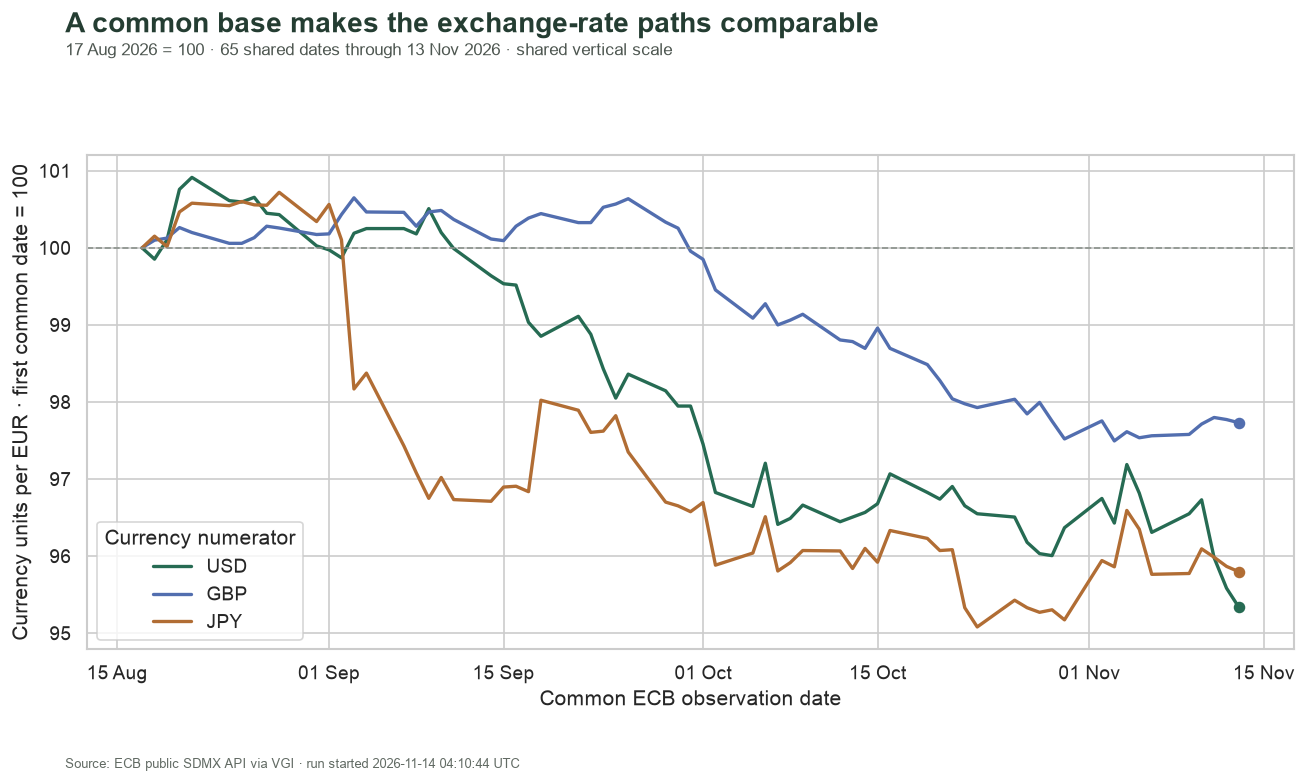

In [23]:
fig, ax = plt.subplots(figsize=(11.5, 6.6))
for currency in CURRENCIES:
    frame = indexed[indexed.currency == currency]
    ax.plot(frame.obs_date, frame.quote_index, color=palette[currency], linewidth=2, label=currency)
    ax.scatter(frame.obs_date.iloc[-1], frame.quote_index.iloc[-1], color=palette[currency], s=35)
ax.axhline(100, color="#8A918B", linewidth=1, linestyle="--")
ax.set(xlabel="Common ECB observation date", ylabel="Currency units per EUR · first common date = 100")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(title="Currency numerator", loc="best", frameon=True)
chart(
    fig,
    "02_rebased_paths",
    "A common base makes the exchange-rate paths comparable",
    f"{first_common:%d %b %Y} = 100 · {common_count} shared dates through {last_common:%d %b %Y} "
    "· shared vertical scale",
    source,
    artifact_dir,
)

In [24]:
ordered = summary.sort_values("quote_change_pct", ascending=False)
most, least = ordered.iloc[0], ordered.iloc[-1]
prose(
    f"Over these common dates, **{most.currency} has the highest quote change "
    f"({most.quote_change_pct:+.2f}%)**, while **{least.currency} has the lowest "
    f"({least.quote_change_pct:+.2f}%)**. These are changes in currency units per euro. "
    f"For {most.currency}, reversing the quote gives **{most.inverse_change_pct:+.2f}% "
    "in EUR per currency unit**, illustrating the direction and denominator change. "
    "The chart connects consecutive shared observation dates; it does not supply missing-day prices."
)

Over these common dates, **GBP has the highest quote change (-2.27%)**, while **USD has the lowest (-4.67%)**. These are changes in currency units per euro. For GBP, reversing the quote gives **+2.32% in EUR per currency unit**, illustrating the direction and denominator change. The chart connects consecutive shared observation dates; it does not supply missing-day prices.

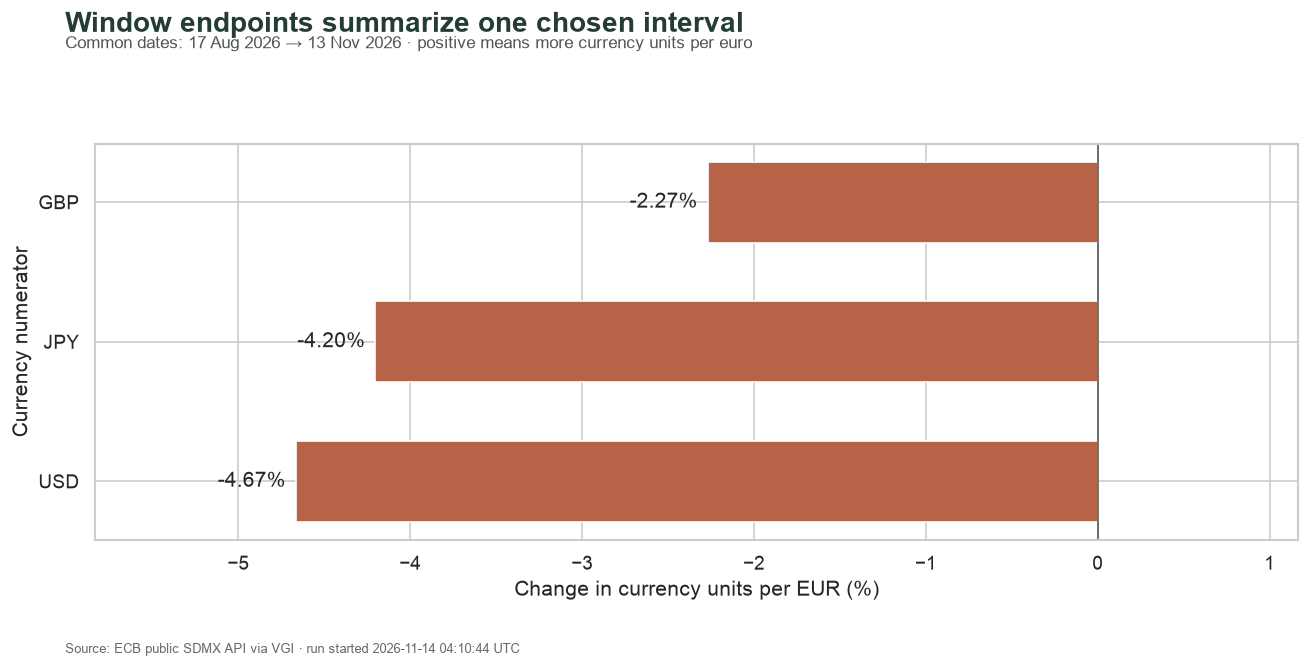

In [25]:
fig, ax = plt.subplots(figsize=(11.5, 5.6))
ordered = summary.sort_values("quote_change_pct")
bar_colors = ["#267253" if value >= 0 else "#B66347" for value in ordered.quote_change_pct]
bars = ax.barh(ordered.currency, ordered.quote_change_pct, color=bar_colors, height=0.58)
ax.axvline(0, color="#555E57", linewidth=1)
ax.bar_label(bars, labels=[f"{value:+.2f}%" for value in ordered.quote_change_pct], padding=6)
lo, hi = min(0, ordered.quote_change_pct.min()), max(0, ordered.quote_change_pct.max())
pad = max(0.3, (hi - lo) * 0.25)
ax.set_xlim(lo - pad, hi + pad)
ax.set(xlabel="Change in currency units per EUR (%)", ylabel="Currency numerator")
chart(
    fig,
    "03_endpoint_changes",
    "Window endpoints summarize one chosen interval",
    f"Common dates: {first_common:%d %b %Y} → {last_common:%d %b %Y} · positive means more currency units per euro",
    source,
    artifact_dir,
)

## Experiment: shorten the lookback to 30 days

Change **only `LOOKBACK_DAYS` from `90` to `30`**, restart, and run all. Predict that
the number of common observations will fall, while the latest raw quotes will stay
the same if the source is unchanged and the resolved end date is the same. The
rebased lines will start at 100 on a new date, so endpoint changes and their ordering
may change. Their direction is not predicted.

Compare the **shared coverage table**, the **rebased paths**, and the **endpoint bar
chart**. This is a sensitivity check on the observation window, not a forecast or a
test of transaction returns. Later live runs can also differ because of source
updates or a new UTC day; the run report records the resolved end date so these
causes can be distinguished. Use the same explicit `END_DATE` in both copies if
running across days. Restore **`LOOKBACK_DAYS = 90`** afterward.

The [execution guide](README.md#execute-and-check-the-experiment) shows how to save
the 30-day run separately without overwriting this notebook.

In [26]:
prose(
    f"**This run's comparison card:** LOOKBACK_DAYS = **{LOOKBACK_DAYS}**, "
    f"resolved END_DATE = **{end_date}**, **{common_count} common dates**. "
    + "; ".join(
        f"{r.currency}: {r.quote_change_pct:+.2f}% ({r.first_quote:,.5g} → {r.last_quote:,.5g} {r.currency}/EUR)"
        for r in summary.sort_values("currency").itertuples()
    )
    + "."
)
artifact_dir.mkdir(parents=True, exist_ok=True)
report = {
    "source": API_URL,
    "mode": "live",
    "run_started_utc": started.isoformat(),
    "observations_loaded_utc": retrieved.isoformat(),
    "currencies": CURRENCIES,
    "lookback_days": LOOKBACK_DAYS,
    "start_date": str(start_date),
    "end_date": str(end_date),
    "sdmx_key": sdmx_key,
    "coverage": coverage.to_dict(orient="records"),
    "summary": summary.to_dict(orient="records"),
}
_ = (artifact_dir / "run_report.json").write_text(json.dumps(report, indent=2, default=str) + "\n")

**This run's comparison card:** LOOKBACK_DAYS = **90**, resolved END_DATE = **2026-11-13**, **65 common dates**. GBP: -2.27% (0.855 → 0.83559 GBP/EUR); JPY: -4.20% (184.59 → 176.83 JPY/EUR); USD: -4.67% (1.1593 → 1.1052 USD/EUR).

In [27]:
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="210"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)